# Bài tập Lab 6 — Máy vectơ hỗ trợ (SVM)

Sáu bài tập, mỗi bài có nhận xét và giải thích cuối cell. Bài 1 và 2 tập trung giải thích lề và vectơ hỗ trợ.

Chạy ô **Chuẩn bị** trước, rồi chạy các cell theo thứ tự. CSV ngoài `data/` có thể được chỉ định trong ô chuẩn bị. Trên Colab, tải lên ba CSV khi được yêu cầu.


## Chuẩn bị


In [1]:
import os
import sys
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_digits, make_classification
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

# Để trống để tìm tự động; có thể chỉ định CSV ngoài thư mục data.
DUONG_DAN_SINH_VIEN = os.environ.get("LAB6_SINH_VIEN", "")
DUONG_DAN_SINH_VIEN_MO_RONG = os.environ.get("LAB6_SINH_VIEN_MO_RONG", "")
DUONG_DAN_VANG_TRANG = os.environ.get("LAB6_VANG_TRANG", "")

def tim_dataset(ten_tep, duong_dan_chi_dinh):
    if duong_dan_chi_dinh:
        tep = Path(duong_dan_chi_dinh).expanduser()
        if not tep.is_file():
            raise FileNotFoundError(f"Khong tim thay dataset: {tep.name}")
        return tep.resolve()
    hien_tai = Path.cwd().resolve()
    cac_goc = []
    if os.environ.get("LAB6_ROOT"):
        cac_goc.append(Path(os.environ["LAB6_ROOT"]))
    cac_goc.extend([hien_tai, hien_tai.parent, hien_tai.parent.parent])
    for goc in cac_goc:
        for tep in [goc / "06. SVM" / "data" / ten_tep,
                    goc / "data" / ten_tep, goc / ten_tep]:
            if tep.is_file():
                return tep.resolve()
    if "google.colab" in sys.modules:
        from google.colab import files
        print(f"Hay tai len {ten_tep}; co the chon ca ba CSV cung luc.")
        files.upload()
        if (hien_tai / ten_tep).is_file():
            return (hien_tai / ten_tep).resolve()
    raise FileNotFoundError(f"Can tep {ten_tep}. Hay chi dinh duong dan trong o Chuan bi.")

def doc_dataset(ten_tep, duong_dan, cac_cot, cot_nhan):
    tep = tim_dataset(ten_tep, duong_dan)
    bang = pd.read_csv(tep)
    if not set(cac_cot).issubset(bang.columns):
        raise ValueError(f"{ten_tep} can cac cot: {', '.join(cac_cot)}")
    so = bang[cac_cot].apply(pd.to_numeric, errors="coerce")
    if not np.isfinite(so.to_numpy(dtype=float)).all():
        raise ValueError(f"{ten_tep} co gia tri thieu hoac khong phai so huu han.")
    if set(so[cot_nhan].unique()) != {0, 1}:
        raise ValueError(f"{ten_tep}: nhan phai gom hai lop 0 va 1.")
    if so[cot_nhan].value_counts().min() < 8:
        raise ValueError(f"{ten_tep}: can du mau moi lop de chia tap va kiem dinh cheo 5 phan.")
    so[cot_nhan] = so[cot_nhan].astype(int)
    print("Dataset:", tep.name, so.shape)
    return so

du_lieu_sinh_vien = doc_dataset("sinh_vien.csv", DUONG_DAN_SINH_VIEN,
    ["gio_on", "diem_giua_ky", "qua_mon"], "qua_mon")
du_lieu_mo_rong = doc_dataset("sinh_vien_mo_rong.csv", DUONG_DAN_SINH_VIEN_MO_RONG,
    ["gio_on", "diem_giua_ky", "chi_tieu", "qua_mon"], "qua_mon")
du_lieu_vang_trang = doc_dataset("hai_vang_trang.csv", DUONG_DAN_VANG_TRANG,
    ["x1", "x2", "nhan"], "nhan")

thu_muc_lab = Path(os.environ.get("LAB6_ROOT", Path.cwd())).resolve()
if "LAB6_ROOT" not in os.environ:
    if thu_muc_lab.name == "code":
        thu_muc_lab = thu_muc_lab.parent
    elif (thu_muc_lab / "06. SVM").is_dir():
        thu_muc_lab = thu_muc_lab / "06. SVM"
thu_muc_hinh = thu_muc_lab / "figures"
thu_muc_hinh.mkdir(parents=True, exist_ok=True)

def tao_24_diem():
    dac_trung, nhan = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                                cluster_std=0.9, random_state=0)
    return dac_trung, 1 - nhan

def chia_vang_trang():
    return train_test_split(du_lieu_vang_trang[["x1", "x2"]],
        du_lieu_vang_trang["nhan"], test_size=0.25, random_state=17,
        stratify=du_lieu_vang_trang["nhan"])

def chia_chu_so():
    anh, nhan = load_digits(return_X_y=True)
    return train_test_split(anh, nhan, test_size=0.25, random_state=17, stratify=nhan)

def tim_rbf(dac_trung_hoc, nhan_hoc, cac_C, cac_gamma):
    # Giữ dữ liệu chưa chuẩn hóa như mục 5 trong PDF để đối chiếu đúng.
    tim = GridSearchCV(SVC(kernel="rbf"), {"C": cac_C, "gamma": cac_gamma},
                       cv=5, scoring="accuracy", n_jobs=1, error_score="raise")
    tim.fit(dac_trung_hoc, nhan_hoc)
    return tim

def in_luoi_rbf(tim):
    bang = pd.DataFrame(tim.cv_results_["params"])
    bang["diem"] = tim.cv_results_["mean_test_score"]
    print(bang.pivot(index="C", columns="gamma", values="diem").round(4).to_string())
    hoa = np.isclose(bang["diem"], tim.best_score_, rtol=0, atol=1e-12)
    print("Cac cap dong diem CV cao nhat:", bang.loc[hoa, ["C", "gamma"]].to_dict("records"))
    print("Cap duoc chon:", tim.best_params_)


Dataset: sinh_vien.csv (120, 3)
Dataset: sinh_vien_mo_rong.csv (120, 4)
Dataset: hai_vang_trang.csv (300, 3)


## Bài 1 — Tính tay khoảng cách tới ranh giới


In [2]:
dac_trung, nhan = tao_24_diem()
svm = SVC(kernel="linear", C=1000).fit(dac_trung, nhan)
trong_so_day_du = svm.coef_[0]
chan_day_du = svm.intercept_[0]
# Đúng yêu cầu: dùng các hệ số được in với 3 chữ số ở mục 2.
trong_so_in = np.round(trong_so_day_du, 3)
chan_in = float(np.round(chan_day_du, 3))
print(f"He so in o muc 2: w1={trong_so_in[0]:.3f}, w2={trong_so_in[1]:.3f}, b={chan_in:.3f}")

def tinh_tay(diem, trong_so, he_so_chan):
    return trong_so[0] * diem[0] + trong_so[1] * diem[1] + he_so_chan

do_dai_in = np.sqrt(trong_so_in[0]**2 + trong_so_in[1]**2)
do_dai_day_du = np.sqrt(trong_so_day_du[0]**2 + trong_so_day_du[1]**2)
print(f"Do rong le theo he so in: {2 / do_dai_in:.6f}")
print(f"Nua do rong le theo he so day du: {1 / do_dai_day_du:.6f}")
print("\nDiem         f(x) tinh tay   Khoang cach (he so in)")
for diem in [(3.0, 3.0), (5.0, 4.5)]:
    gia_tri = tinh_tay(diem, trong_so_in, chan_in)
    print(f"{str(diem):13s} {gia_tri:+.6f} {abs(gia_tri)/do_dai_in:.6f}")
print("\nBa vecto ho tro: dung toa do day du cua du lieu")
print("Chi so   Lop     f(x) he so in   d he so in   d he so day du")
khoang_cach_ho_tro = []
for chi_so in svm.support_:
    diem = dac_trung[chi_so]
    gia_tri_in = tinh_tay(diem, trong_so_in, chan_in)
    gia_tri_day_du = tinh_tay(diem, trong_so_day_du, chan_day_du)
    khoang_cach = abs(gia_tri_day_du) / do_dai_day_du
    khoang_cach_ho_tro.append(khoang_cach)
    print(f"{chi_so:6d} {nhan[chi_so]:5d} {gia_tri_in:+.6f}"
          f" {abs(gia_tri_in)/do_dai_in:.6f} {khoang_cach:.6f}")
do_lech = np.max(np.abs(np.array(khoang_cach_ho_tro) - 1/do_dai_day_du))
print(f"Sai lech lon nhat so voi nua le (he so day du): {do_lech:.8f}")
print("\nNHẬN XÉT VÀ GIẢI THÍCH:")
print("Với hệ số đã in, f(3, 3) dương nên điểm ở phía lớp 1; f(5, 4.5) âm nên ở phía lớp 0. "
      "Độ lớn của f(x) chưa phải khoảng cách Euclid và cũng không phải xác suất; phải chia cho độ dài vectơ w.")
print("Đường ranh giới là w·x+b=0; hai mép lề có w·x+b=+1 và -1. "
      "Khoảng cách từ mỗi mép tới ranh giới bằng 1/||w||, nên toàn bộ lề rộng 2/||w||.")
print(f"Ba vectơ hỗ trợ của bộ 24 điểm tách được nằm gần hai mép lề, nên khoảng cách của chúng "
      f"xấp xỉ {1/do_dai_day_du:.6f}, tức một nửa độ rộng lề. Sai lệch số đo lớn nhất là {do_lech:.8f}.")
print("Không nên ép kết quả số thực bằng nhau tuyệt đối: hệ số in trong PDF đã làm tròn, "
      "tọa độ in cũng đã làm tròn, và bộ giải SVM có dung sai. Bảng phụ dùng hệ số đầy đủ để phân biệt các nguồn sai số.")
print("Kết luận nằm trên mép lề áp dụng cho ví dụ tách được này. Với lề mềm, vectơ hỗ trợ "
      "còn có thể nằm trong lề hoặc bị phân loại sai, nên không phải mọi vectơ hỗ trợ luôn cách ranh giới đúng nửa lề.")


He so in o muc 2: w1=-0.831, w2=-0.355, b=4.820
Do rong le theo he so in: 2.213243
Nua do rong le theo he so day du: 1.106282

Diem         f(x) tinh tay   Khoang cach (he so in)
(3.0, 3.0)    +1.262000 1.396556
(5.0, 4.5)    -0.932500 1.031924

Ba vecto ho tro: dung toa do day du cua du lieu
Chi so   Lop     f(x) he so in   d he so in   d he so day du
    18     0 -0.999161 1.105692 1.106396
    10     1 +1.000036 1.106662 1.106169
    13     1 +1.000815 1.107523 1.106509
Sai lech lon nhat so voi nua le (he so day du): 0.00022677

NHẬN XÉT VÀ GIẢI THÍCH:
Với hệ số đã in, f(3, 3) dương nên điểm ở phía lớp 1; f(5, 4.5) âm nên ở phía lớp 0. Độ lớn của f(x) chưa phải khoảng cách Euclid và cũng không phải xác suất; phải chia cho độ dài vectơ w.
Đường ranh giới là w·x+b=0; hai mép lề có w·x+b=+1 và -1. Khoảng cách từ mỗi mép tới ranh giới bằng 1/||w||, nên toàn bộ lề rộng 2/||w||.
Ba vectơ hỗ trợ của bộ 24 điểm tách được nằm gần hai mép lề, nên khoảng cách của chúng xấp xỉ 1.106282, tức một

## Bài 2 — Thêm một điểm và vai trò vectơ hỗ trợ


In [3]:
dac_trung_goc, nhan_goc = tao_24_diem()
svm_goc = SVC(kernel="linear", C=1000).fit(dac_trung_goc, nhan_goc)
trong_so_goc = svm_goc.coef_[0]
chan_goc = svm_goc.intercept_[0]
print(f"Goc: w1={trong_so_goc[0]:.6f}, w2={trong_so_goc[1]:.6f}, b={chan_goc:.6f}")
ket_qua_them = []
for diem_moi in [(-1.0, -1.0), (4.5, 4.0)]:
    # Hai thí nghiệm độc lập, mỗi lần chỉ thêm một điểm vào 24 điểm gốc.
    dac_trung_them = np.vstack([dac_trung_goc, diem_moi])
    nhan_them = np.append(nhan_goc, 1)
    mo_hinh = SVC(kernel="linear", C=1000).fit(dac_trung_them, nhan_them)
    trong_so = mo_hinh.coef_[0]
    he_so_chan = mo_hinh.intercept_[0]
    gia_tri_cu = trong_so_goc[0]*diem_moi[0] + trong_so_goc[1]*diem_moi[1] + chan_goc
    la_ho_tro = len(dac_trung_goc) in mo_hinh.support_
    # Chuẩn hóa pháp tuyến để so đường thẳng, không phụ thuộc độ lớn chung của hệ số.
    duong_cu = np.r_[trong_so_goc, chan_goc] / np.linalg.norm(trong_so_goc)
    duong_moi = np.r_[trong_so, he_so_chan] / np.linalg.norm(trong_so)
    sai_khac = np.max(np.abs(duong_moi - duong_cu))
    thay_doi = not np.allclose(duong_moi, duong_cu, atol=0.005, rtol=0)
    print(f"\nThem diem {diem_moi}, lop 1")
    print(f"w1={trong_so[0]:.6f}, w2={trong_so[1]:.6f}, b={he_so_chan:.6f}")
    print(f"f(x) theo duong cu = {gia_tri_cu:+.6f}")
    print("Diem moi la vecto ho tro:", "co" if la_ho_tro else "khong")
    print("So vecto ho tro:", len(mo_hinh.support_))
    print(f"Sai khac he so duong da chuan hoa: {sai_khac:.6f}")
    print("Ranh gioi thay doi (dung sai 0.005):", "co" if thay_doi else "gan nhu khong")
    ket_qua_them.append((diem_moi, gia_tri_cu, la_ho_tro, thay_doi))
print("\nNHẬN XÉT VÀ GIẢI THÍCH:")
for diem, gia_tri, la_ho_tro, thay_doi in ket_qua_them:
    print(f"Điểm {diem} có nhãn 1 và f(x) theo đường cũ bằng {gia_tri:.4f}. "
          f"Sau học lại, điểm này {'là' if la_ho_tro else 'không là'} vectơ hỗ trợ; "
          f"ranh giới {'thay đổi rõ' if thay_doi else 'gần như giữ nguyên'} theo dung sai đã nêu.")
print("Điểm (-1, -1) nằm xa về phía lớp 1 và thỏa f(x)>1, nên đã ở ngoài lề đúng phía. "
      "Ràng buộc mới không buộc đường tối ưu cũ phải dịch chuyển; điểm đó không có trọng số hỗ trợ khác 0.")
print("Điểm (4.5, 4) gần đường cũ và có f(x)<1. Với nhãn 1, nó vi phạm yêu cầu nằm ngoài "
      "mép +1; SVM phải cân bằng lại độ rộng lề và mức phạt C=1000, nên tập vectơ hỗ trợ và đường ranh giới đổi.")
print("Vectơ hỗ trợ là các điểm có hệ số đối ngẫu khác 0, đóng góp vào w. Thêm điểm không tự động "
      "làm đổi ranh giới: vị trí và nhãn so với lề mới là yếu tố quyết định. C lớn là phạt nặng vi phạm, "
      "không phải bảo đảm toán học rằng mọi bộ dữ liệu đều tách được. Sai khác rất nhỏ giữa hai lần tối ưu có thể do dung sai bộ giải.")


Goc: w1=-0.831357, w2=-0.354868, b=4.820361

Them diem (-1.0, -1.0), lop 1
w1=-0.831357, w2=-0.354868, b=4.820361
f(x) theo duong cu = +6.006586
Diem moi la vecto ho tro: khong
So vecto ho tro: 3
Sai khac he so duong da chuan hoa: 0.000000
Ranh gioi thay doi (dung sai 0.005): gan nhu khong

Them diem (4.5, 4.0), lop 1
w1=-2.603014, w2=-0.806843, b=15.940939
f(x) theo duong cu = -0.340220
Diem moi la vecto ho tro: co
So vecto ho tro: 2
Sai khac he so duong da chuan hoa: 0.516791
Ranh gioi thay doi (dung sai 0.005): co

NHẬN XÉT VÀ GIẢI THÍCH:
Điểm (-1.0, -1.0) có nhãn 1 và f(x) theo đường cũ bằng 6.0066. Sau học lại, điểm này không là vectơ hỗ trợ; ranh giới gần như giữ nguyên theo dung sai đã nêu.
Điểm (4.5, 4.0) có nhãn 1 và f(x) theo đường cũ bằng -0.3402. Sau học lại, điểm này là vectơ hỗ trợ; ranh giới thay đổi rõ theo dung sai đã nêu.
Điểm (-1, -1) nằm xa về phía lớp 1 và thỏa f(x)>1, nên đã ở ngoài lề đúng phía. Ràng buộc mới không buộc đường tối ưu cũ phải dịch chuyển; điểm đó k

## Bài 3 — Kernel đa thức


In [4]:
tap_hoc, tap_kiem_tra, nhan_hoc, nhan_kiem_tra = chia_vang_trang()
cac_tim_poly = {}
bang_ket_qua = []
for bac in [2, 3, 4]:
    tim = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="poly", degree=bac)),
        {"svc__C": [0.1, 1, 10, 100]}, cv=5, scoring="accuracy", n_jobs=1, error_score="raise")
    tim.fit(tap_hoc, nhan_hoc)
    cac_tim_poly[bac] = tim
    bang_ket_qua.append({"bac": bac, "C_tot_nhat": tim.best_params_["svc__C"],
        "diem_CV": tim.best_score_, "accuracy_kiem_tra": tim.score(tap_kiem_tra, nhan_kiem_tra)})
bang = pd.DataFrame(bang_ket_qua)
print(bang.to_string(index=False, float_format=lambda so: f"{so:.4f}"))
diem_cao_nhat = bang["diem_CV"].max()
cac_bac_hoa = bang.loc[np.isclose(bang["diem_CV"], diem_cao_nhat, atol=1e-12, rtol=0), "bac"].tolist()
bac_tot_nhat = min(cac_bac_hoa)
print("Cac bac dong diem CV cao nhat:", cac_bac_hoa)
print("Bac duoc chon (lay bac nho nhat khi hoa):", bac_tot_nhat)
rbf = tim_rbf(tap_hoc, nhan_hoc, [0.1, 1, 10, 100], [0.01, 0.1, 1, 10])
accuracy_poly = cac_tim_poly[bac_tot_nhat].score(tap_kiem_tra, nhan_kiem_tra)
accuracy_rbf = rbf.score(tap_kiem_tra, nhan_kiem_tra)
print("RBF muc 5, tham so:", rbf.best_params_)
print(f"RBF: CV={rbf.best_score_:.4f}, accuracy kiem tra={accuracy_rbf:.4f}")
print(f"Chenh lech accuracy poly - RBF: {accuracy_poly-accuracy_rbf:+.4f}")
print("\nNHẬN XÉT VÀ GIẢI THÍCH:")
print(f"Theo điểm CV trên tập học, chọn bậc {bac_tot_nhat}; các bậc cùng điểm cao nhất là {cac_bac_hoa}. "
      "Quy ước hòa điểm là lấy bậc nhỏ nhất. Trong từng bậc, GridSearchCV chọn C đứng trước nếu điểm bằng nhau.")
print(f"Kernel đa thức đã chọn có accuracy {accuracy_poly:.4f}, RBF mục 5 là {accuracy_rbf:.4f}. "
      f"Trong lần thử này, đa thức {'vượt' if accuracy_poly > accuracy_rbf else 'không vượt'} RBF trên tập kiểm tra.")
print("Chuẩn hóa nằm trong pipeline nên được học riêng ở mỗi fold, tránh dùng thông tin của phần thẩm định. "
      "Bậc cao hơn không bảo đảm tốt hơn: C và bậc cùng chi phối độ phức tạp. RBF đối chiếu được chạy đúng cách "
      "chưa chuẩn hóa ở mục 5; đây là so hai quy trình theo đề, không tách riêng tác động của kernel.")
print("Chọn bậc và C bằng CV trên tập học; các accuracy kiểm tra chỉ dùng báo cáo, không dùng để đổi lựa chọn. "
      "CV tốt nhất sau dò cũng có thể lạc quan vì đã thử nhiều ứng viên; một lần chia dữ liệu không chứng minh mô hình nào luôn tốt hơn.")


 bac  C_tot_nhat  diem_CV  accuracy_kiem_tra
   2           1   0.5422             0.5067
   3           1   0.8178             0.8267
   4         100   0.5156             0.4800
Cac bac dong diem CV cao nhat: [3]
Bac duoc chon (lay bac nho nhat khi hoa): 3


RBF muc 5, tham so: {'C': 10, 'gamma': 1}
RBF: CV=0.8711, accuracy kiem tra=0.9200
Chenh lech accuracy poly - RBF: -0.0933

NHẬN XÉT VÀ GIẢI THÍCH:
Theo điểm CV trên tập học, chọn bậc 3; các bậc cùng điểm cao nhất là [3]. Quy ước hòa điểm là lấy bậc nhỏ nhất. Trong từng bậc, GridSearchCV chọn C đứng trước nếu điểm bằng nhau.
Kernel đa thức đã chọn có accuracy 0.8267, RBF mục 5 là 0.9200. Trong lần thử này, đa thức không vượt RBF trên tập kiểm tra.
Chuẩn hóa nằm trong pipeline nên được học riêng ở mỗi fold, tránh dùng thông tin của phần thẩm định. Bậc cao hơn không bảo đảm tốt hơn: C và bậc cùng chi phối độ phức tạp. RBF đối chiếu được chạy đúng cách chưa chuẩn hóa ở mục 5; đây là so hai quy trình theo đề, không tách riêng tác động của kernel.
Chọn bậc và C bằng CV trên tập học; các accuracy kiểm tra chỉ dùng báo cáo, không dùng để đổi lựa chọn. CV tốt nhất sau dò cũng có thể lạc quan vì đã thử nhiều ứng viên; một lần chia dữ liệu không chứng minh mô hình nào luôn tốt hơn.


## Bài 4 — Dò lưới mịn


In [5]:
tap_hoc, tap_kiem_tra, nhan_hoc, nhan_kiem_tra = chia_vang_trang()
tim_thua = tim_rbf(tap_hoc, nhan_hoc, [0.1, 1, 10, 100], [0.01, 0.1, 1, 10])
tim_min = tim_rbf(tap_hoc, nhan_hoc, [3, 10, 30], [0.3, 1, 3])
print("LUOI THUA - DIEM CV")
in_luoi_rbf(tim_thua)
print("\nLUOI MIN - DIEM CV")
in_luoi_rbf(tim_min)
accuracy_thua = tim_thua.score(tap_kiem_tra, nhan_kiem_tra)
accuracy_min = tim_min.score(tap_kiem_tra, nhan_kiem_tra)
print(f"\nCV luoi thua: {tim_thua.best_score_:.6f}; CV luoi min: {tim_min.best_score_:.6f}")
print(f"Accuracy kiem tra: luoi thua={accuracy_thua:.4f}, luoi min={accuracy_min:.4f}")
print(f"Chenh lech CV so voi moc in 0.8711: {tim_min.best_score_-0.8711:+.6f}")
print("\nNHẬN XÉT VÀ GIẢI THÍCH:")
chenh_cv = tim_min.best_score_ - tim_thua.best_score_
print(f"Lưới mịn {'cải thiện' if chenh_cv > 1e-12 else 'không cải thiện'} điểm CV so với "
      f"lưới thưa chạy lại; chênh lệch thật là {chenh_cv:+.6f}. Mốc 0.8711 trong PDF đã làm tròn, "
      "nên một chênh lệch vài phần triệu so với mốc in không được xem là cải thiện.")
print(f"Accuracy kiểm tra {'không đổi' if np.isclose(accuracy_min, accuracy_thua) else 'thay đổi'} "
      f"từ {accuracy_thua:.4f} thành {accuracy_min:.4f}.")
print("Cặp (10, 1) của lưới thưa cũng nằm trong lưới mịn; với cùng các fold, lưới mịn ít nhất "
      "có ứng viên đó để đối chiếu. Thêm ứng viên có thể tìm được điểm tốt hơn nhưng tốn thêm 9×5 lần học "
      "và một lần refit. Dò quá kỹ có thể chỉ tận dụng dao động của các fold, không bảo đảm tăng khả năng tổng quát.")
print("Hai lần dò chỉ dùng tập học, không dùng nhãn kiểm tra để chọn C và gamma. Khi hòa điểm, "
      "GridSearchCV chọn cặp đầu tiên theo thứ tự lưới; không dùng accuracy kiểm tra để phá hòa.")


LUOI THUA - DIEM CV
gamma   0.01    0.10    1.00    10.00
C                                    
0.1    0.6578  0.8044  0.8444  0.8578
1.0    0.8044  0.8178  0.8667  0.8667
10.0   0.8178  0.8400  0.8711  0.8311
100.0  0.8178  0.8533  0.8711  0.7467
Cac cap dong diem CV cao nhat: [{'C': 10.0, 'gamma': 1.0}, {'C': 100.0, 'gamma': 1.0}]
Cap duoc chon: {'C': 10, 'gamma': 1}

LUOI MIN - DIEM CV
gamma     0.3     1.0     3.0
C                            
3      0.8533  0.8711  0.8667
10     0.8489  0.8711  0.8667
30     0.8622  0.8756  0.8533
Cac cap dong diem CV cao nhat: [{'C': 30, 'gamma': 1.0}]
Cap duoc chon: {'C': 30, 'gamma': 1}

CV luoi thua: 0.871111; CV luoi min: 0.875556
Accuracy kiem tra: luoi thua=0.9200, luoi min=0.9200
Chenh lech CV so voi moc in 0.8711: +0.004456

NHẬN XÉT VÀ GIẢI THÍCH:
Lưới mịn cải thiện điểm CV so với lưới thưa chạy lại; chênh lệch thật là +0.004444. Mốc 0.8711 trong PDF đã làm tròn, nên một chênh lệch vài phần triệu so với mốc in không được xem là cải thiện

## Bài 5 — Ma trận nhầm lẫn và ảnh chữ số dự đoán sai


MA TRAN NHAM LAN: HANG LA NHAN THAT, COT LA NHAN DOAN
doan   0   1   2   3   4   5   6   7   8   9
that                                        
0     45   0   0   0   0   0   0   0   0   0
1      0  46   0   0   0   0   0   0   0   0
2      0   0  44   0   0   0   0   0   0   0
3      0   0   0  46   0   0   0   0   0   0
4      0   0   0   0  44   0   0   0   1   0
5      0   0   0   0   0  46   0   0   0   0
6      0   0   0   0   0   0  45   0   0   0
7      0   0   0   0   0   0   0  44   0   1
8      0   1   0   0   0   0   0   0  42   0
9      0   0   0   1   0   0   0   0   0  44
Accuracy: 0.9911
So anh sai: 4 / 450
Cac cap bi nham (that -> doan):
 4 -> 8: 1 anh
 7 -> 9: 1 anh
 8 -> 1: 1 anh
 9 -> 3: 1 anh
Da luu hinh: figures/bai5_anh_006_that_9_doan_3.png


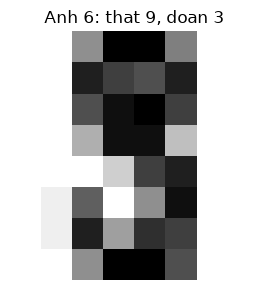

Da luu hinh: figures/bai5_anh_018_that_8_doan_1.png


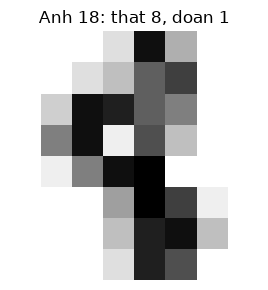

Da luu hinh: figures/bai5_anh_161_that_4_doan_8.png

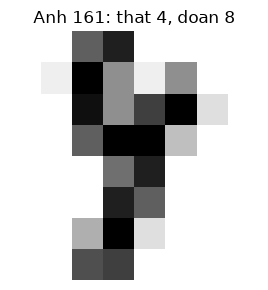

Da luu hinh: figures/bai5_anh_428_that_7_doan_9.png


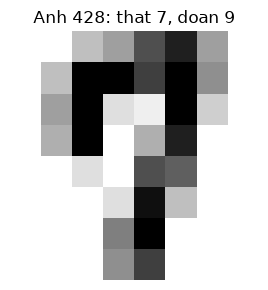


NHẬN XÉT VÀ GIẢI THÍCH:
SVM nhầm 4 trên 450 ảnh. Đường chéo là dự đoán đúng; ô hàng i, cột j ngoài đường chéo là chữ i bị đoán thành j, không được đọc ngược.
Cặp 4 → 8 có 1 ảnh: các nét nối khép gần nhau có thể tạo hình giống hai vòng của chữ 8. Đây là giả thuyết hình dạng cần đối chiếu với ảnh vừa hiển thị, không phải nguyên nhân đã được mô hình chứng minh.
Cặp 7 → 9 có 1 ảnh: nét ngang hoặc nét móc có thể làm phần trên giống vòng của chữ 9. Đây là giả thuyết hình dạng cần đối chiếu với ảnh vừa hiển thị, không phải nguyên nhân đã được mô hình chứng minh.
Cặp 8 → 1 có 1 ảnh: hai vòng hẹp hoặc không rõ có thể làm nét giữa trội lên giống chữ 1. Đây là giả thuyết hình dạng cần đối chiếu với ảnh vừa hiển thị, không phải nguyên nhân đã được mô hình chứng minh.
Cặp 9 → 3 có 1 ảnh: nét đóng vòng hoặc nét trái mờ có thể khiến phần bên phải giống chữ 3. Đây là giả thuyết hình dạng cần đối chiếu với ảnh vừa hiển thị, không phải nguyên nhân đã được mô hình chứng minh.
Ảnh chỉ có 8×8 ô; SVM RBF s

In [6]:
tap_hoc, tap_kiem_tra, nhan_hoc, nhan_kiem_tra = chia_chu_so()
svm = SVC(kernel="rbf").fit(tap_hoc, nhan_hoc)
du_doan = svm.predict(tap_kiem_tra)
ma_tran = confusion_matrix(nhan_kiem_tra, du_doan, labels=np.arange(10))
bang_nham_lan = pd.DataFrame(ma_tran, index=np.arange(10), columns=np.arange(10))
bang_nham_lan.index.name = "that"
bang_nham_lan.columns.name = "doan"
print("MA TRAN NHAM LAN: HANG LA NHAN THAT, COT LA NHAN DOAN")
print(bang_nham_lan.to_string())
print(f"Accuracy: {accuracy_score(nhan_kiem_tra, du_doan):.4f}")
chi_so_sai = np.flatnonzero(du_doan != nhan_kiem_tra)
print(f"So anh sai: {len(chi_so_sai)} / {len(nhan_kiem_tra)}")
print("Cac cap bi nham (that -> doan):")
cac_cap_sai = []
for lop_that in range(10):
    for lop_doan in range(10):
        if lop_that != lop_doan and ma_tran[lop_that, lop_doan] > 0:
            so_anh = int(ma_tran[lop_that, lop_doan])
            cac_cap_sai.append((lop_that, lop_doan, so_anh))
            print(f" {lop_that} -> {lop_doan}: {so_anh} anh")
for chi_so in chi_so_sai:
    lop_that = int(nhan_kiem_tra[chi_so])
    lop_doan = int(du_doan[chi_so])
    hinh, truc = plt.subplots(figsize=(3, 3))
    plt.imshow(tap_kiem_tra[chi_so].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    truc.set_title(f"Anh {chi_so}: that {lop_that}, doan {lop_doan}")
    truc.axis("off")
    hinh.tight_layout()
    ten_hinh = f"bai5_anh_{chi_so:03d}_that_{lop_that}_doan_{lop_doan}.png"
    hinh.savefig(thu_muc_hinh / ten_hinh, dpi=160, bbox_inches="tight")
    print(f"Da luu hinh: figures/{ten_hinh}")
    plt.show()
    plt.close(hinh)
print("\nNHẬN XÉT VÀ GIẢI THÍCH:")
print(f"SVM nhầm {len(chi_so_sai)} trên {len(nhan_kiem_tra)} ảnh. Đường chéo là dự đoán đúng; "
      "ô hàng i, cột j ngoài đường chéo là chữ i bị đoán thành j, không được đọc ngược.")
gia_thuyet = {
    (9, 3): "nét đóng vòng hoặc nét trái mờ có thể khiến phần bên phải giống chữ 3",
    (8, 1): "hai vòng hẹp hoặc không rõ có thể làm nét giữa trội lên giống chữ 1",
    (4, 8): "các nét nối khép gần nhau có thể tạo hình giống hai vòng của chữ 8",
    (7, 9): "nét ngang hoặc nét móc có thể làm phần trên giống vòng của chữ 9",
}
for lop_that, lop_doan, so_anh in cac_cap_sai:
    ly_do = gia_thuyet.get((lop_that, lop_doan), "nét viết, độ dày hoặc vị trí các nét có thể giống lớp được đoán")
    print(f"Cặp {lop_that} → {lop_doan} có {so_anh} ảnh: {ly_do}. Đây là giả thuyết hình dạng cần "
          "đối chiếu với ảnh vừa hiển thị, không phải nguyên nhân đã được mô hình chứng minh.")
if not cac_cap_sai:
    print("Lần chạy này không có ảnh sai để lưu hoặc phân tích; không tạo ảnh lỗi giả.")
print("Ảnh chỉ có 8×8 ô; SVM RBF so sự giống nhau trong 64 giá trị pixel, không hiểu quy tắc viết chữ. "
      "Các biến thể nét viết có thể nằm gần ảnh của lớp khác. Một lỗi của một cặp trong 450 ảnh chưa đủ "
      "kết luận đó là cặp luôn hay nhầm; cần thêm dữ liệu để đánh giá mức phổ biến.")


## Bài 6 — Thời gian huấn luyện trên dữ liệu lớn


In [7]:
SO_LAN_DO = 3
bang_thoi_gian = []
for so_mau in [2000, 5000, 10000, 20000]:
    dac_trung, nhan = make_classification(n_samples=so_mau, n_features=20, random_state=0)
    dong = {"so_mau": so_mau}
    print(f"Dang do n={so_mau} ...", flush=True)
    for ten, tao_mo_hinh in [("SVC", SVC), ("LinearSVC", LinearSVC)]:
        cac_lan_do = []
        so_lan_chua_hoi_tu = 0
        for lan in range(SO_LAN_DO):
            # Giữ mặc định của hai lớp theo đề. Seed cho bộ giải nếu dùng ngẫu nhiên.
            np.random.seed(0)
            mo_hinh = tao_mo_hinh()
            with warnings.catch_warnings(record=True) as canh_bao:
                warnings.simplefilter("always")
                bat_dau = time.perf_counter()
                mo_hinh.fit(dac_trung, nhan)
                thoi_gian = time.perf_counter() - bat_dau
            chua_hoi_tu = any(issubclass(w.category, ConvergenceWarning) for w in canh_bao)
            so_lan_chua_hoi_tu += int(chua_hoi_tu)
            for canh in canh_bao:
                if not issubclass(canh.category, ConvergenceWarning):
                    warnings.warn(canh.message, canh.category)
            cac_lan_do.append(thoi_gian)
        dong[ten + "_giay"] = float(np.median(cac_lan_do))
        dong[ten + "_lan_chua_hoi_tu"] = so_lan_chua_hoi_tu
    bang_thoi_gian.append(dong)
bang = pd.DataFrame(bang_thoi_gian)
print("\nTHOI GIAN FIT: TRUNG VI 3 LAN, DON VI GIAY")
print(bang.to_string(index=False, float_format=lambda so: f"{so:.6f}"))
print("\nTY LE THOI GIAN SO VOI CO MAU TRUOC")
for truoc, sau in zip(bang_thoi_gian[:-1], bang_thoi_gian[1:]):
    he_so_mau = sau["so_mau"] / truoc["so_mau"]
    print(f"{truoc['so_mau']} -> {sau['so_mau']} (x{he_so_mau:.1f} mau): "
          f"SVC x{sau['SVC_giay']/truoc['SVC_giay']:.2f}, "
          f"LinearSVC x{sau['LinearSVC_giay']/truoc['LinearSVC_giay']:.2f}")
print("\nNHẬN XÉT VÀ GIẢI THÍCH:")
for truoc, sau in zip(bang_thoi_gian[1:-1], bang_thoi_gian[2:]):
    print(f"Khi tăng từ {truoc['so_mau']} lên {sau['so_mau']} mẫu (gấp đôi), thời gian SVC "
          f"gấp {sau['SVC_giay']/truoc['SVC_giay']:.2f} lần và LinearSVC "
          f"gấp {sau['LinearSVC_giay']/truoc['LinearSVC_giay']:.2f} lần.")
print("Bước 2.000 lên 5.000 là tăng 2,5 lần, không phải gấp đôi. Số liệu chỉ tính thời gian fit; "
      "không cộng thời gian sinh dữ liệu, tạo mô hình hay in bảng. Mỗi lần đo tạo mô hình mới và lấy trung vị ba lần.")
print("SVC mặc định dùng kernel RBF và xử lý quan hệ giữa các mẫu, thường tăng chi phí nhanh hơn khi n lớn. "
      "LinearSVC giải bài toán tuyến tính với 20 đặc trưng, thường phù hợp dữ liệu lớn hơn. "
      "Đây là hai mô hình và bộ giải khác nhau; nhanh hơn không đồng nghĩa accuracy tốt hơn.")
print("Các bộ dữ liệu được sinh lại cho từng n, không phải các tập con lồng nhau. Độ khó bài toán, phiên bản thư viện, "
      "phần cứng và tiến trình nền đều ảnh hưởng thời gian. Không suy ra một quy luật tăng chính xác chỉ từ bốn phép đo.")
so_canh_bao = sum(dong['SVC_lan_chua_hoi_tu'] + dong['LinearSVC_lan_chua_hoi_tu'] for dong in bang_thoi_gian)
print(f"Có {so_canh_bao} lượt fit báo chưa hội tụ. " +
      ("Cần tăng giới hạn vòng lặp và đo lại cả bảng trước khi so tốc độ ở cùng điều kiện hội tụ."
       if so_canh_bao else "Các lượt đo không phát sinh cảnh báo chưa hội tụ."))


Dang do n=2000 ...


Dang do n=5000 ...


Dang do n=10000 ...


Dang do n=20000 ...



THOI GIAN FIT: TRUNG VI 3 LAN, DON VI GIAY
 so_mau  SVC_giay  SVC_lan_chua_hoi_tu  LinearSVC_giay  LinearSVC_lan_chua_hoi_tu
   2000  0.020158                    0        0.001273                          0
   5000  0.100033                    0        0.003284                          0
  10000  1.182031                    0        0.005076                          0
  20000  3.090651                    0        0.011517                          0

TY LE THOI GIAN SO VOI CO MAU TRUOC
2000 -> 5000 (x2.5 mau): SVC x4.96, LinearSVC x2.58
5000 -> 10000 (x2.0 mau): SVC x11.82, LinearSVC x1.55
10000 -> 20000 (x2.0 mau): SVC x2.61, LinearSVC x2.27

NHẬN XÉT VÀ GIẢI THÍCH:
Khi tăng từ 5000 lên 10000 mẫu (gấp đôi), thời gian SVC gấp 11.82 lần và LinearSVC gấp 1.55 lần.
Khi tăng từ 10000 lên 20000 mẫu (gấp đôi), thời gian SVC gấp 2.61 lần và LinearSVC gấp 2.27 lần.
Bước 2.000 lên 5.000 là tăng 2,5 lần, không phải gấp đôi. Số liệu chỉ tính thời gian fit; không cộng thời gian sinh dữ liệu, tạo m